[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch07-mini_workbook.ipynb)

# The attention weights of `The cat sat` when `chat` is written

In a sequence-to-sequence translation of `The cat sat` into French, each
English word has one encoder state. When `chat` is the next French word, the
decoder's state is scored against each of the three encoder states, and the
softmax of the scores gives the weights. Which English word has the most weight, and what is
lost when the whole sentence is one vector of 256 numbers?

In [1]:
#@title Setup: run this cell first
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

WORDS = ["The", "cat", "sat"]
# The three encoder states of NLP week 4, page 21 (its decoder state is H_DEC in step 1): invented numbers of width 3.
ENC = np.array([[0.1, 0.2, 0.1], [0.8, 0.1, 0.7], [0.2, 0.3, 0.2]])
PER_WORD, CONTEXT = 100, 256  # numbers per word embedding, numbers in one context vector
plt.rcParams.update({"xtick.labelsize": 9, "ytick.labelsize": 9})


def softmax(s):  # e to each score, divided by the sum: weights with a sum of 1
    e = np.exp(np.asarray(s, dtype=float) - np.max(s))
    return e / e.sum()


def attention_row(h_dec):  # scores, weights and context vector for one decoder state
    s = ENC @ np.asarray(h_dec, dtype=float)
    a = softmax(s)
    print("scores :", ", ".join(f"{w} {v:.2f}" for w, v in zip(WORDS, s)))
    print("weights:", ", ".join(f"{w} {v:.3f}" for w, v in zip(WORDS, a)))
    print("context:", "(" + ", ".join(f"{v:.3f}" for v in a @ ENC) + ")")
    fig, ax = plt.subplots(figsize=(4.2, 2.6), layout="constrained")
    bars = ax.bar(WORDS, a, color=["#9e9e9e" if v < a.max() else "#a6192e" for v in a])
    ax.bar_label(bars, labels=[f"{v:.3f}" for v in a], fontsize=9)
    ax.set(ylim=(0, 1), ylabel="weight", title="weights over the English words")
    plt.show()


def bottleneck(lengths):  # numbers in a sentence, against one context vector and against all encoder states
    n = np.array(sorted(lengths))
    x = np.arange(len(n))
    fig, ax = plt.subplots(figsize=(5.4, 2.8), layout="constrained")
    ax.bar(x - 0.27, PER_WORD * n, 0.27, color="#9e9e9e", label="numbers in the sentence")
    ax.bar(x, [CONTEXT] * len(n), 0.27, color="#a6192e", label="one context vector")
    ax.bar(x + 0.27, CONTEXT * n, 0.27, color="#0f7c80", label="all encoder states (attention)")
    ax.set(xticks=x, xticklabels=[f"{k} words" for k in n], yscale="log", ylim=(PER_WORD, None), ylabel="numbers")
    ax.legend(fontsize=8, loc="upper left")
    plt.show()
    for k in n:
        print(f"{k} words: {PER_WORD * k:,} numbers into {CONTEXT}, a ratio of {PER_WORD * k / CONTEXT:.1f} to 1; "
              f"with attention {CONTEXT * k:,} numbers kept")


def alignment(sharpness):  # one row of weights per French word over the English words, invented states
    en, fr = ["the", "black", "cat"], ["le", "chat", "noir"]
    E = np.eye(3)
    D = sharpness * E[[0, 2, 1]]  # the state of le equals that of the, chat that of cat, noir that of black
    A = np.array([softmax(E @ d) for d in D])
    fig, ax = plt.subplots(figsize=(3.6, 3.2), layout="constrained")
    ax.imshow(A, cmap="Reds", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{A[i, j]:.3f}", ha="center", va="center", fontsize=10,
                    color="white" if A[i, j] > 0.6 else "black")
    ax.set(xticks=range(3), xticklabels=en, yticks=range(3), yticklabels=fr, title=f"sharpness {sharpness}")
    ax.set_xlabel("English word", fontsize=9)
    ax.set_ylabel("French word", fontsize=9)
    plt.show()
    return A


def gap_curve(scores=None):  # the weight of the first of two words against the gap between their scores
    g = np.linspace(-6, 6, 241)
    fig, ax = plt.subplots(figsize=(4.6, 2.8), layout="constrained")
    ax.plot(g, 1 / (1 + np.exp(-g)), color="#0f7c80")
    pairs = [[0.9, 0.1], [5.0, 1.0]] + ([list(scores)] if scores is not None and list(scores) not in ([0.9, 0.1], [5.0, 1.0]) else [])
    for pair in pairs:
        w, gap = softmax(pair)[0], pair[0] - pair[1]
        ax.plot(gap, w, "o", color="#a6192e" if pair in ([0.9, 0.1], [5.0, 1.0]) else "#000000")
        ax.annotate(f"({pair[0]}, {pair[1]}): {w:.3f}", (gap, w), textcoords="offset points",
                    xytext=(-92, 2) if gap > 2 else (8, -12), fontsize=8)
    ax.set(xlabel="gap between the two scores", ylabel="weight of word 1", ylim=(0, 1.05))
    plt.show()

## 1. Three scores, three weights, one context vector

Each score is the dot product of the decoder state with one encoder state.
The softmax of the three scores gives weights with a sum of 1, and the
context vector is the weighted sum of the encoder states. Run the cell: which English
word has the largest weight? Then set `H_DEC` to `[0.1, 0.2, 0.1]`, the state
of `The`, and run it again: how far apart are the three weights now?

scores : The 0.09, cat 0.94, sat 0.20
weights: The 0.224, cat 0.525, sat 0.251
context: (0.493, 0.173, 0.440)


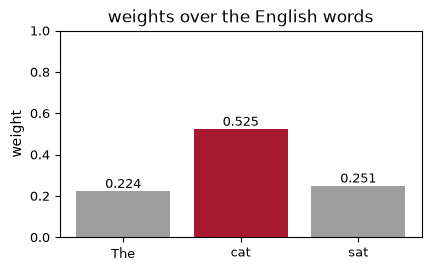

In [2]:
H_DEC = [0.5, -0.2, 0.8]
attention_row(H_DEC)

### Solution

In [3]:
a, a_the = softmax(ENC @ np.array([0.5, -0.2, 0.8])), softmax(ENC @ np.array([0.1, 0.2, 0.1]))
display(Markdown(f"With the decoder state of NLP week 4, `cat` has the largest weight, {a[1]:.3f}, and `The` and "
                 f"`sat` have {a[0]:.3f} and {a[2]:.3f}. With the state of `The` the three weights are {a_the[0]:.3f}, "
                 f"{a_the[1]:.3f} and {a_the[2]:.3f}, within {a_the.max() - a_the.min():.3f} of each other: short "
                 "vectors give small scores, and small scores give nearly equal weights."))

With the decoder state of NLP week 4, `cat` has the largest weight, 0.525, and `The` and `sat` have 0.224 and 0.251. With the state of `The` the three weights are 0.317, 0.354 and 0.330, within 0.037 of each other: short vectors give small scores, and small scores give nearly equal weights.

## 2. One context vector for every sentence length

Without attention, all the decoder has of the English sentence is one context
vector of 256 numbers, whatever the sentence's length. At 100 numbers per
word, longer sentences have more to squeeze into those 256. With attention,
every encoder state is kept. Run the cell, then add `50` to `LENGTHS` and run
it again: what is the ratio for a sentence of 50 words?

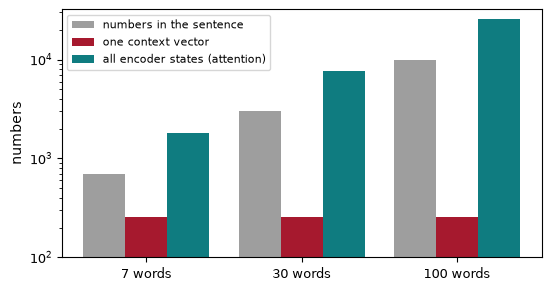

7 words: 700 numbers into 256, a ratio of 2.7 to 1; with attention 1,792 numbers kept
30 words: 3,000 numbers into 256, a ratio of 11.7 to 1; with attention 7,680 numbers kept
100 words: 10,000 numbers into 256, a ratio of 39.1 to 1; with attention 25,600 numbers kept


In [4]:
LENGTHS = [7, 30, 100]
bottleneck(LENGTHS)

### Solution

In [5]:
n = 50
display(Markdown(f"A sentence of {n} words has {PER_WORD * n:,} numbers, a ratio of {PER_WORD * n / CONTEXT:.1f} to 1 "
                 f"into one context vector of {CONTEXT}; at 30 words the ratio is {PER_WORD * 30 / CONTEXT:.1f} to 1. "
                 f"With attention, {CONTEXT * n:,} numbers are kept in the {n} encoder states, and the ratio is "
                 f"{PER_WORD / CONTEXT:.2f} to 1 at every length."))

A sentence of 50 words has 5,000 numbers, a ratio of 19.5 to 1 into one context vector of 256; at 30 words the ratio is 11.7 to 1. With attention, 12,800 numbers are kept in the 50 encoder states, and the ratio is 0.39 to 1 at every length.

## 3. An alignment matrix for a whole translation

Each French word has its own row of weights over the English words, and the
rows together are an alignment matrix. In `the black cat` and `le chat noir`
the French adjective is after the noun, so the rows of `chat` and `noir` are
swapped against the English order. The states are invented, and all scores
are multiplied by `SHARPNESS`. Run the cell: what weight of `chat` lies on
`cat`? Then set `SHARPNESS` to `1` and run it again.

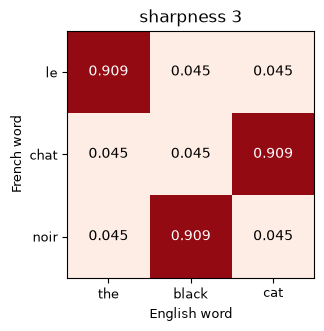

In [6]:
SHARPNESS = 3
A = alignment(SHARPNESS)

### Solution

In [7]:
w3, w1 = softmax([0, 0, 3])[2], softmax([0, 0, 1])[2]
display(Markdown(f"At sharpness 3, {w3:.3f} of the weight of `chat` lies on `cat`; at sharpness 1, {w1:.3f}, and "
                 f"`the` and `black` have {(1 - w1) / 2:.3f} each. The pattern of the matrix is the same, the off-diagonal "
                 "cells for `chat` and `noir`; larger scores give a sharper row."))

At sharpness 3, 0.909 of the weight of `chat` lies on `cat`; at sharpness 1, 0.576, and `the` and `black` have 0.212 each. The pattern of the matrix is the same, the off-diagonal cells for `chat` and `noir`; larger scores give a sharper row.

## Appendix. Why softmax: the gap between two scores

For two words with scores s₁ and s₂, softmax gives word 1 the weight

e^s₁ / (e^s₁ + e^s₂) = 1 / (1 + e^−(s₁ − s₂)),

which depends on the gap s₁ − s₂ alone. The curve is that weight for gaps
from −6 to 6; the two points are the examples of the lecture's appendix,
scores (0.9, 0.1) and (5.0, 1.0).

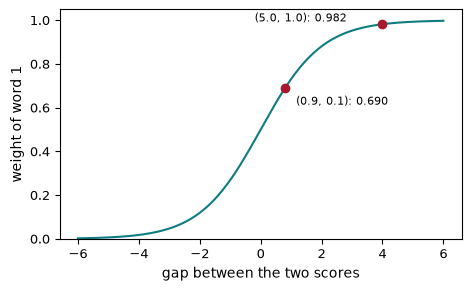

In [8]:
gap_curve()

**Exercise.** Set `SCORES` to `[2.0, 0.0]`, then to `[0.2, 0.0]`. What weight
has word 1 each time, and which gap gives word 1 a weight above 0.95?

scores [0.9, 0.1]: weights 0.690, 0.310


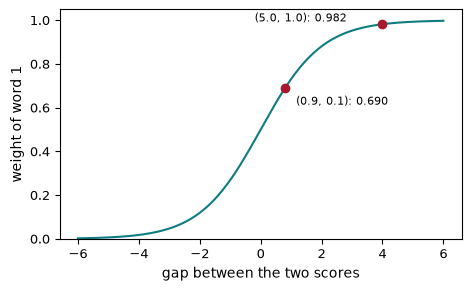

In [9]:
SCORES = [0.9, 0.1]
print(f"scores {SCORES}: weights " + ", ".join(f"{v:.3f}" for v in softmax(SCORES)))
gap_curve(SCORES)

### Solution

In [10]:
g95 = float(np.log(0.95 / 0.05))
display(Markdown(f"Scores (2.0, 0.0) give word 1 {softmax([2.0, 0.0])[0]:.3f}, and (0.2, 0.0) give it "
                 f"{softmax([0.2, 0.0])[0]:.3f}. Word 1 has more than 0.95 once the gap passes {g95:.2f}: "
                 f"the scores (5.0, 1.0), a gap of 4, give {softmax([5.0, 1.0])[0]:.3f}."))

Scores (2.0, 0.0) give word 1 0.881, and (0.2, 0.0) give it 0.550. Word 1 has more than 0.95 once the gap passes 2.94: the scores (5.0, 1.0), a gap of 4, give 0.982.